# Session 1 lecture: Why data analytics matters

<p class="lead">
Data analytics means making decisions with evidence instead of guesswork, and explaining that evidence so people act on it. This lecture shows why that matters, how an analysis is organised, and why you must always look at the data, not only its summary numbers.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/01_why_data_analytics_lecture.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## What you will be able to do

1. Name the four levels of analytics and give a business example of each.
2. Explain, with a real story, how data changed a decision and how it can fail.
3. Turn a vague request into a question with a **decision**, **population**, **period** and **measure**.
4. Show with code why summary statistics are not enough, using Anscombe's quartet and the Datasaurus Dozen.
5. Name the most common ways numbers mislead.

This lecture uses the [Foundations](../foundations/index.md) pages as its reading. In the **Lab** you practise the Python behind every demonstration here.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first: being wrong is how you learn what to check. **Check your understanding** boxes are short questions to answer in your own words.

---

## Part 1: What is data analytics?

Data analytics turns raw records into answers to business questions. It works at four levels, each building on the one before.

| Level | Question it answers | Everyday example |
|---|---|---|
| **Descriptive** | What happened? | Sales fell last quarter. |
| **Diagnostic** | Why did it happen? | The fall came almost entirely from one region after a competitor opened. |
| **Predictive** | What is likely to happen next? | If nothing changes, that region will keep losing sales. |
| **Prescriptive** | What should we do about it? | Test a local loyalty offer in that region before changing national prices. |

Most of this course works at the first two levels, done **properly**: a clear question, trustworthy data, correct calculations, honest charts and a recommendation a manager can act on. Later sessions add uncertainty and simple prediction.

> **Check your understanding**
>
> Which level is each statement?
>
> 1. "Deliveries in the North got slower because the new carrier skips Saturday collections."
> 2. "We expect about 400 returns in December."
> 3. "Move the slow carrier's routes to the faster one for one month and measure the effect."
> 4. "We shipped 12,000 parcels in October."


---

## Part 2: Real stories where data changed the outcome

Each story teaches one habit you will use in every session. Read the full versions in [Why data analytics matters](../foundations/index.md).

| Story | What happened | The habit it teaches |
|---|---|---|
| **John Snow**, London, 1854 | Mapping cholera deaths showed them clustered around one water pump. Its handle was removed. | A simple, well-chosen picture can overturn what "everyone knows". |
| **Florence Nightingale**, 1850s | Her diagrams showed most soldiers died of preventable disease in hospitals, not of wounds. | Analysis only changes things when decision-makers understand it. |
| **Moneyball**, baseball, 2002 | A low-budget team found undervalued players by measuring on-base percentage. | Measuring the *right* thing can matter more than having the most money. |
| **Walmart**, hurricane, 2004 | Sales patterns before earlier storms guided what to stock before a new one. | Past patterns can guide everyday operational decisions. |
| **Google Flu Trends**, 2008–2015 | Estimating flu from searches worked, then failed badly and was shut down. | More data is not automatically better data. Every result needs validation. |

> **Predict, then reveal**
>
> Four of these stories are successes; one is a failure. Before reading the last row, ask yourself: what could make a model that once worked stop working? Then read the last row and the full story in Foundations.

> **Check your understanding**
>
> Snow and Nightingale both *drew* their evidence. Why might a chart persuade a decision-maker when a table of the same numbers does not?


---

## Part 3: From question to recommendation

Every analysis in this course follows the same seven steps. The full version is in [the analytical workflow](../course/workflow.md).

| Step | Ask | Keep as evidence |
|---|---|---|
| 1. Business question | Who must decide what, and by when? | The decision and a one-sentence question |
| 2. Data understanding | What does each row represent? What is missing? | Grain, keys, units, scope |
| 3. Preparation | What changes are needed, and can someone repeat them? | Untouched original data and a change log |
| 4. Analysis | Which comparison or metric answers the question? | Metric definition, filters, calculation |
| 5. Validation | Do totals reconcile? Can I explain odd values? | Spot checks, count and total checks |
| 6. Visualisation | Can the audience see the key comparison at a glance? | A labelled chart with period, units and population |
| 7. Recommendation | What action follows, and what is still uncertain? | Action, one caveat, a follow-up measure |

### Step 1 in detail: a question you can answer

A manager says: *"Sales feel uneven across our customer groups."* That is a feeling, not a question. A question you can answer with data names four things:

| Part | Ask yourself | Example |
|---|---|---|
| **Decision** | What will someone do differently? | Choose one customer segment to investigate next month |
| **Population** | Which records count? | All order lines in the sales table |
| **Period** | Which dates? | Orders placed in 2023, 2024 and 2025 |
| **Measure** | What will we compare? | Total sales by customer segment |

> *"Which customer segment had the highest total sales for orders placed in 2023–2025, so we can choose one segment to investigate next month?"*

> **Check your understanding**
>
> A colleague asks: *"Is the new website working?"* Which of the four parts are missing? Suggest one value for each.


---

## Part 4: Always plot your data — Anscombe's quartet

In 1973 the statistician **Francis Anscombe** made four small datasets to make one point. We build them in code, compute their summary statistics, and only then look at them.

The code below stores all four datasets in one table. Each row is one point: which set it belongs to (`set`), and its `x` and `y` values.

In [1]:
import pandas as pd

# Anscombe's quartet (1973): four small datasets, eleven points each.
x = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
anscombe = pd.concat([
    pd.DataFrame({"set": "I",   "x": x, "y": [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]}),
    pd.DataFrame({"set": "II",  "x": x, "y": [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]}),
    pd.DataFrame({"set": "III", "x": x, "y": [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]}),
    pd.DataFrame({"set": "IV",  "x": [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],
                  "y": [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]}),
], ignore_index=True)

print("Rows, columns:", anscombe.shape)
anscombe.head()

Rows, columns: (44, 3)


,set,x,y
0,I,10,8.04
1,I,8,6.95
2,I,13,7.58
3,I,9,8.81
4,I,11,8.33


Now the summary statistics for each set. `groupby("set")` splits the table into the four sets; `agg` computes several summaries for each one.

In [2]:
summary = anscombe.groupby("set").agg(
    mean_x=("x", "mean"),
    mean_y=("y", "mean"),
    sd_x=("x", "std"),
    sd_y=("y", "std"),
)
summary["correlation"] = anscombe.groupby("set")[["x", "y"]].apply(lambda d: d["x"].corr(d["y"]))
summary.round(2)

,mean_x,mean_y,sd_x,sd_y,correlation
set,,,,,
I,9.0,7.5,3.32,2.03,0.82
II,9.0,7.5,3.32,2.03,0.82
III,9.0,7.5,3.32,2.03,0.82
IV,9.0,7.5,3.32,2.03,0.82


Finally, the straight line that best fits each set. `np.polyfit(x, y, 1)` returns the slope and the intercept of that line.

In [3]:
import numpy as np

for name, points in anscombe.groupby("set"):
    slope, intercept = np.polyfit(points["x"], points["y"], 1)
    print(f"Set {name:>3}: best-fit line  y = {intercept:.2f} + {slope:.3f} x")

Set   I: best-fit line  y = 3.00 + 0.500 x
Set  II: best-fit line  y = 3.00 + 0.500 x
Set III: best-fit line  y = 3.00 + 0.500 x
Set  IV: best-fit line  y = 3.00 + 0.500 x


> **Predict, then reveal**
>
> Read the outputs above. The four sets share their means, spreads, correlation and best-fit line. Sketch what you think a scatter plot of each set looks like. Will the four pictures be similar? Then run the next cell.

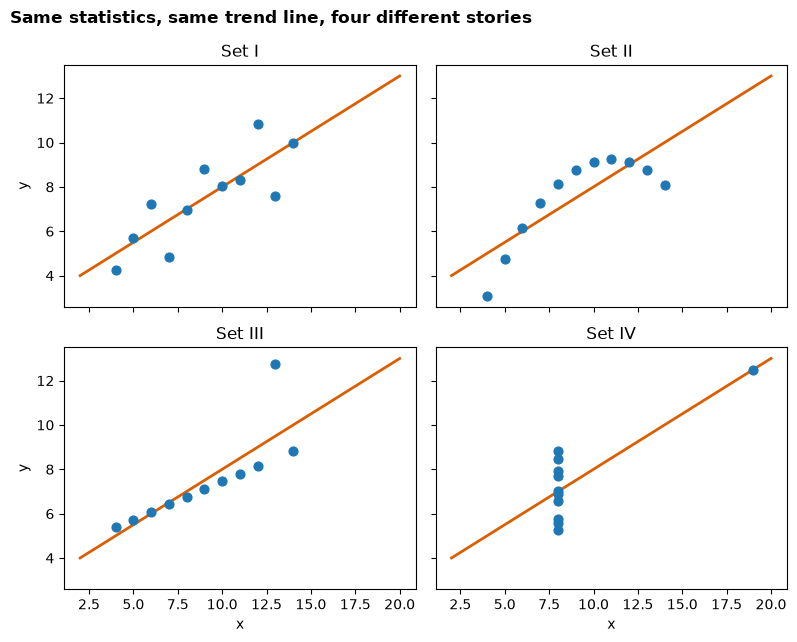

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(8, 6.5), sharex=True, sharey=True)
line_x = np.array([2, 20])
for ax, (name, points) in zip(axes.flat, anscombe.groupby("set")):
    slope, intercept = np.polyfit(points["x"], points["y"], 1)
    ax.plot(line_x, intercept + slope * line_x, color="#d95f02", linewidth=2)
    ax.scatter(points["x"], points["y"], s=40, color="#1f78b4", zorder=3)
    ax.set_title(f"Set {name}")
for ax in axes[1]:
    ax.set_xlabel("x")
for ax in axes[:, 0]:
    ax.set_ylabel("y")
fig.suptitle("Same statistics, same trend line, four different stories", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

| Set | What the picture shows | What the statistics hide |
|---|---|---|
| **I** | A loose, roughly straight-line relationship | Nothing: the summary describes it well |
| **II** | A smooth curve | The relationship is not a straight line |
| **III** | A perfect line except for one outlier | One unusual point drags the trend line |
| **IV** | Almost every point has the same x; one far point creates the "trend" | Remove that point and there is no trend to measure |

> **Remember**
>
> Summary statistics compress data, and compression throws information away. A chart shows you what was thrown away. Plot first, then summarise.

> **Check your understanding**
>
> In set IV, what happens to the correlation if the one point far to the right is a data-entry error and you remove it? Why can you not even compute it?


---

## Part 5: The Datasaurus Dozen

In 2017 **Justin Matejka and George Fitzmaurice** pushed Anscombe's idea further. Starting from a dinosaur drawn with data points, they nudged the points step by step into twelve other shapes while keeping the summary statistics almost identical.

The next cell downloads their data from a fixed public address and checks the file's fingerprint, so everyone gets exactly the same version.

In [5]:
import hashlib
import io
import urllib.request

import pandas as pd

# The Datasaurus Dozen (Matejka and Fitzmaurice, 2017), from the open-source
# datasauRus package (MIT licence). The link points to one fixed version, and the
# fingerprint check confirms we got exactly that file.
DATASAURUS_URL = ("https://raw.githubusercontent.com/jumpingrivers/datasauRus/"
                  "94f3c3a82660e256b84f70961f50dc0e216757de/inst/extdata/DatasaurusDozen-Long.tsv")
DATASAURUS_SHA256 = "c8c4792c3ed15238ba07dad6ab778adc79d72e3e1324ead4d8c1ae52849780f8"

file_bytes = urllib.request.urlopen(DATASAURUS_URL).read()
assert hashlib.sha256(file_bytes).hexdigest() == DATASAURUS_SHA256, "Unexpected file: ask your instructor."
dozen = pd.read_csv(io.BytesIO(file_bytes), sep="\t")

print("Rows, columns:", dozen.shape)
print("Datasets:", dozen["dataset"].nunique())
dozen.head()

Rows, columns: (1846, 3)
Datasets: 13


,dataset,x,y
0,dino,55.3846,97.1795
1,dino,51.5385,96.0256
2,dino,46.1538,94.4872
3,dino,42.8205,91.4103
4,dino,40.7692,88.3333


> **Predict, then reveal**
>
> The table has thirteen datasets. Their names (`dino`, `star`, `circle`, …) are a hint. First look at the statistics in the next cell. Would you have guessed the datasets had different shapes from these numbers alone?

In [6]:
dozen_summary = dozen.groupby("dataset").agg(
    mean_x=("x", "mean"),
    mean_y=("y", "mean"),
    sd_x=("x", "std"),
    sd_y=("y", "std"),
)
dozen_summary["correlation"] = dozen.groupby("dataset")[["x", "y"]].apply(lambda d: d["x"].corr(d["y"]))
dozen_summary.round(2)

,mean_x,mean_y,sd_x,sd_y,correlation
dataset,,,,,
away,54.27,47.83,16.77,26.94,-0.06
bullseye,54.27,47.83,16.77,26.94,-0.07
circle,54.27,47.84,16.76,26.93,-0.07
dino,54.26,47.83,16.77,26.94,-0.06
dots,54.26,47.84,16.77,26.93,-0.06
h_lines,54.26,47.83,16.77,26.94,-0.06
high_lines,54.27,47.84,16.77,26.94,-0.07
slant_down,54.27,47.84,16.77,26.94,-0.07
slant_up,54.27,47.83,16.77,26.94,-0.07


Now draw one small scatter plot per dataset. Charts like this, one per group on the same axes, are called **small multiples**.

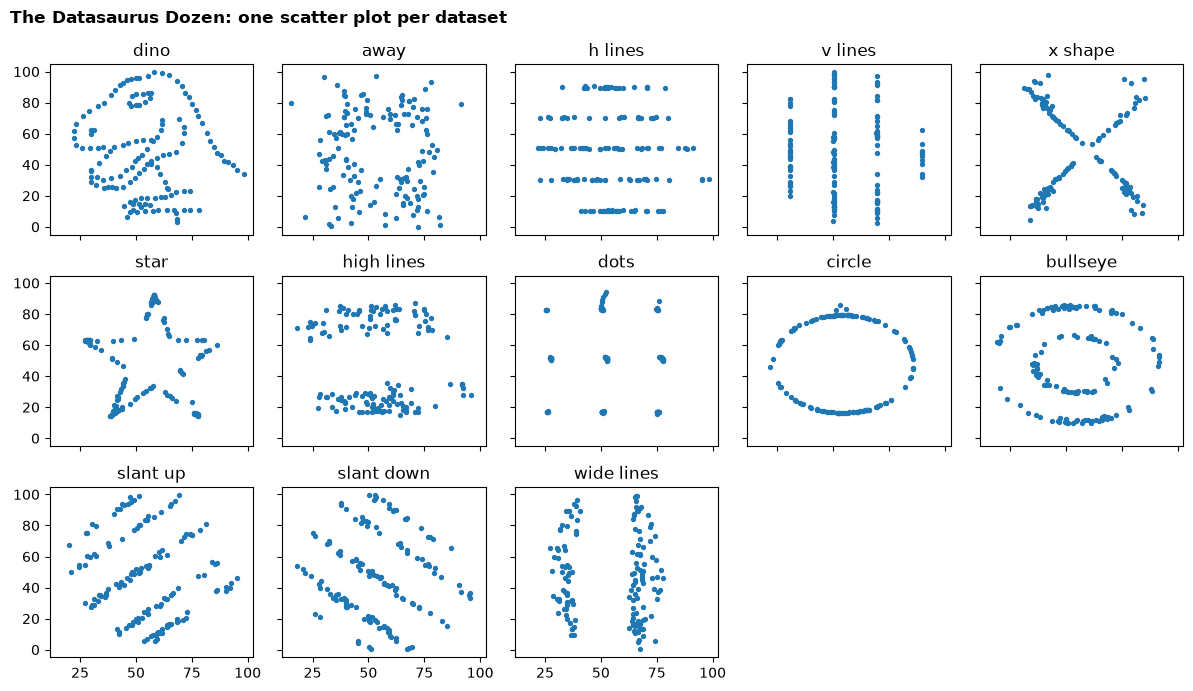

In [7]:
import matplotlib.pyplot as plt

names = dozen["dataset"].unique()
fig, axes = plt.subplots(3, 5, figsize=(12, 7), sharex=True, sharey=True)
for ax in axes.flat:
    ax.set_visible(False)
for ax, name in zip(axes.flat, names):
    points = dozen[dozen["dataset"] == name]
    ax.set_visible(True)
    ax.scatter(points["x"], points["y"], s=8)
    ax.set_title(name.replace("_", " "))
fig.suptitle("The Datasaurus Dozen: one scatter plot per dataset", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

A report saying *"x and y are essentially unrelated, centred around the same values"* would be true for every panel, including the dinosaur.

> **At work**
>
> You will rarely meet a dinosaur in a sales report. You will meet the same problem in everyday forms: an average delivery time that hides a group of customers waiting weeks; one huge order that makes a quiet month look like growth; two stores with the same average sales but very different patterns. See [Statistics are not enough](../foundations/statistics-are-not-enough.md).

> **Check your understanding**
>
> Why are the thirteen panels drawn with the **same** axes? What could go wrong if each panel chose its own axis range?


---

## Part 6: A preview of how numbers mislead

Numbers feel objective, but the same data can tell very different stories depending on how it is summarised and drawn. Here is one trap, live. Both charts below show the **same two numbers**.

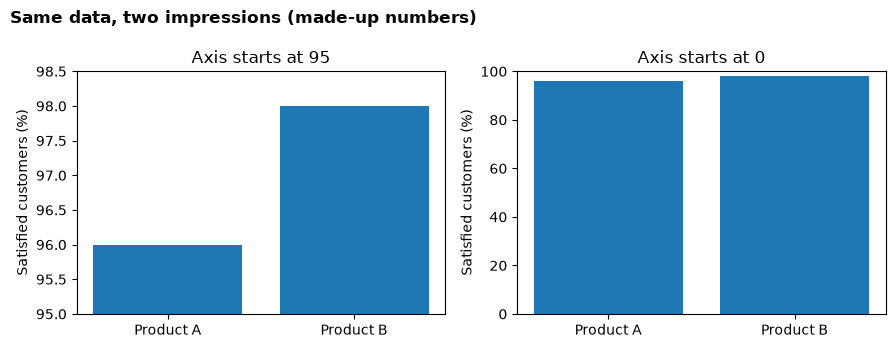

In [8]:
products = ["Product A", "Product B"]
satisfaction = [96, 98]  # made-up percentages

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.5))
left.bar(products, satisfaction, color="#1f78b4")
left.set_ylim(95, 98.5)
left.set_title("Axis starts at 95")
right.bar(products, satisfaction, color="#1f78b4")
right.set_ylim(0, 100)
right.set_title("Axis starts at 0")
for ax in (left, right):
    ax.set_ylabel("Satisfied customers (%)")
fig.suptitle("Same data, two impressions (made-up numbers)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

We judge bars by their **length**, so bar charts should start at zero. On the left, Product B looks several times better; on the right you see the truth: two products almost the same.

The full list of traps is in [How statistics can mislead](../foundations/misleading-statistics.md). Later sessions return to each one with real data.

| Trap | One-line warning | Where we meet it again |
|---|---|---|
| Correlation is not causation | Two things moving together may share a hidden cause | Correlation and regression |
| Simpson's paradox | A total can reverse the story of every part | Metrics and KPIs |
| Misleading axes | Where the axis starts changes the impression | Visualisation principles |
| Cherry-picked time windows | The chosen start and end dates can create any trend | Time series and trends |
| Which average? | Mean and median can tell different stories | Descriptive statistics |
| Percentages without the base | "Up 200%" means little without the counts | Marketing case |
| Survivorship bias | The records you see may be only the survivors | Business cases |

> **A checklist for any number you are shown**
>
> 1. **Compared to what?**
> 2. **Who or what is included?**
> 3. **What is the denominator?**
> 4. **Could something else explain it?**
> 5. **How is it drawn?**


---

## Summary

- Analytics answers four kinds of question: what happened, why, what next and what to do.
- Good analysis starts from a **decision**, and a good question names a decision, population, period and measure.
- The seven-step workflow keeps evidence at each step so someone else can check your work.
- Different data can share identical summary statistics. **Always plot your data.**
- Numbers mislead through causation claims, mixing groups, axes, time windows, averages, missing bases and survivors.

---

## Quiz

Answer these in your own words. We go through them at the start of the next lecture.

1. Name the four levels of analytics, and give a one-line business example of the **diagnostic** level.
2. Google Flu Trends worked for a while and then failed. Give one reason, and the habit this teaches.
3. Rewrite *"How are our stores doing?"* as an analytical question that names a decision, population, period and measure.
4. Two datasets have the same mean, standard deviation and correlation. Can you conclude they look alike? What should you do?
5. In Anscombe's set III, what single feature of the data changes the best-fit line?
6. Why should a bar chart's value axis start at zero, while a line chart's axis may not?
7. A report says *"Customers who used our app spent 30% more."* Give one explanation other than "the app made them spend more".
8. In the seven-step workflow, what is the difference between **analysis** and **validation**?

---

## In the Lab

The Lab notebook, [Session 1 lab](01_why_data_analytics_lab.md), has three parts:

1. **Guided:** Colab and the Python you need: variables, lists, tables, filters, groups and a first chart.
2. **Independent:** recreate the Anscombe statistics and plots yourself, and rewrite a workplace decision as an analytical question.
3. **Challenge:** investigate the Datasaurus Dozen and look for any statistic that tells the datasets apart.

Next session: [Data, grain and the DataFrame](02_data_and_grain_lecture.md).